   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB
None
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)

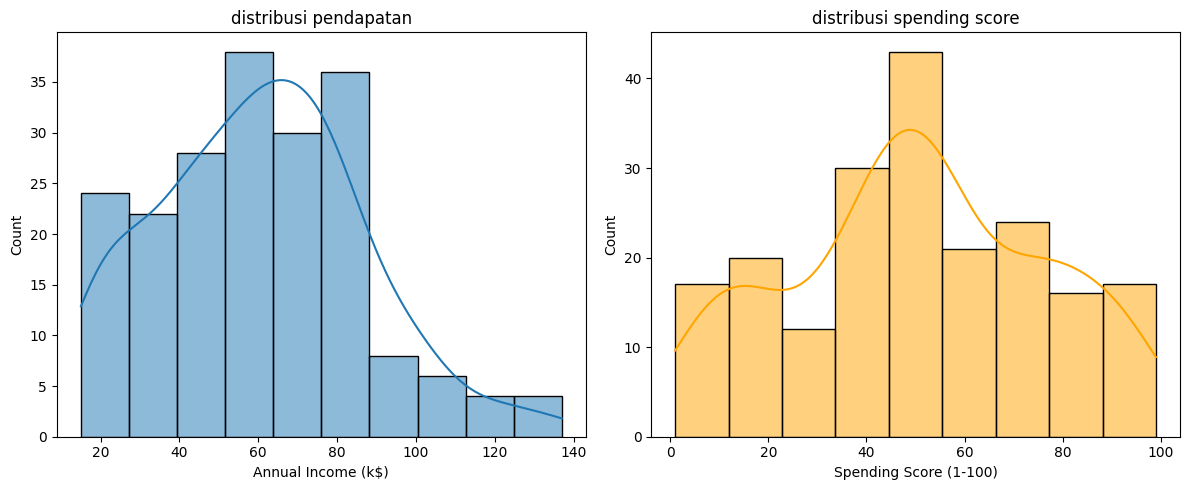

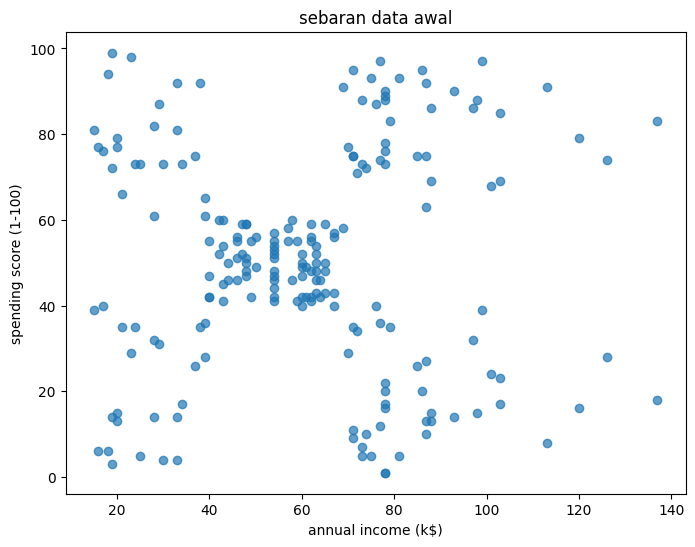

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

df = pd.read_csv('Mall_Customers.csv')
print(df.head())
print(df.info())
print(df.describe())
print('missing values:', df.isnull().sum().sum())
print('duplikat:', df.duplicated().sum())

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['Annual Income (k$)'], kde=True)
plt.title('distribusi pendapatan')
plt.subplot(1, 2, 2)
sns.histplot(df['Spending Score (1-100)'], kde=True, color='orange')
plt.title('distribusi spending score')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], alpha=0.7)
plt.xlabel('annual income (k$)')
plt.ylabel('spending score (1-100)')
plt.title('sebaran data awal')
plt.show()

Pertanyaan EDA
tidak ada missing value atau baris duplikat di dataset ini

rentang pendapatan dari 15k sampe 137k dollar, sedangkan spending score dari 1 sampe 99

terlihat ada beberapa kelompok cluster yg cukup terpisah di scatter plot, misal kelompok income rendah/tinggi dgn spending beda-beda

   Annual Income (k$)  Spending Score (1-100)
0           -1.738999               -0.434801
1           -1.738999                1.195704
2           -1.700830               -1.715913
3           -1.700830                1.040418
4           -1.662660               -0.395980
       Annual Income (k$)  Spending Score (1-100)
count        2.000000e+02            2.000000e+02
mean        -2.131628e-16           -1.465494e-16
std          1.002509e+00            1.002509e+00
min         -1.738999e+00           -1.910021e+00
25%         -7.275093e-01           -5.997931e-01
50%          3.587926e-02           -7.764312e-03
75%          6.656748e-01            8.851316e-01
max          2.917671e+00            1.894492e+00


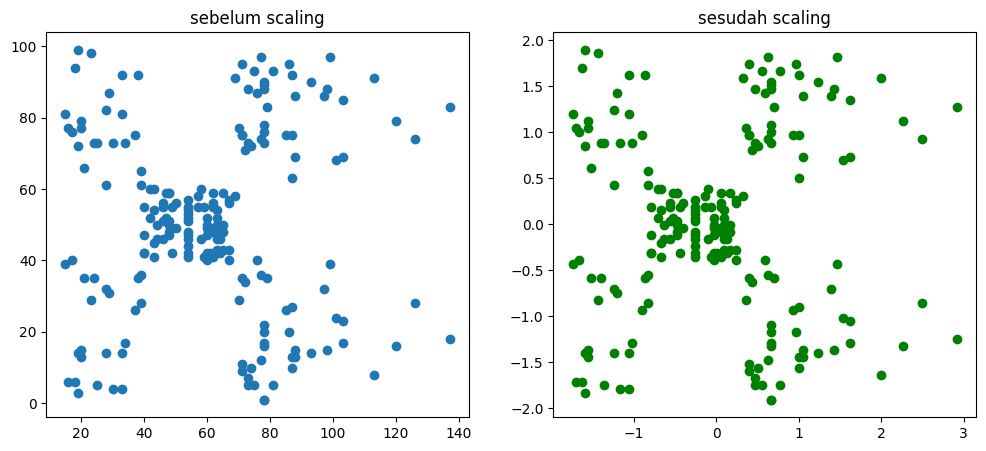

In [7]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=['Annual Income (k$)', 'Spending Score (1-100)'])

print(X_scaled_df.head())
print(X_scaled_df.describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'])
axes[0].set_title('sebelum scaling')
axes[1].scatter(X_scaled_df['Annual Income (k$)'], X_scaled_df['Spending Score (1-100)'], color='green')
axes[1].set_title('sesudah scaling')
plt.show()

Alasan Fitur
fitur annual income & spending score dipilih karena lgsg merepresentasikan perilaku belanja customer. customerid ga dipakai krn cuma id unik yg ga punya makna matematis buat jarak cluster.

jumlah anggota tiap label:  3    88
-1    35
 4    30
 5    14
 0    12
 6     9
 2     7
 1     5
Name: count, dtype: int64
jumlah cluster: 7, jumlah noise: 35


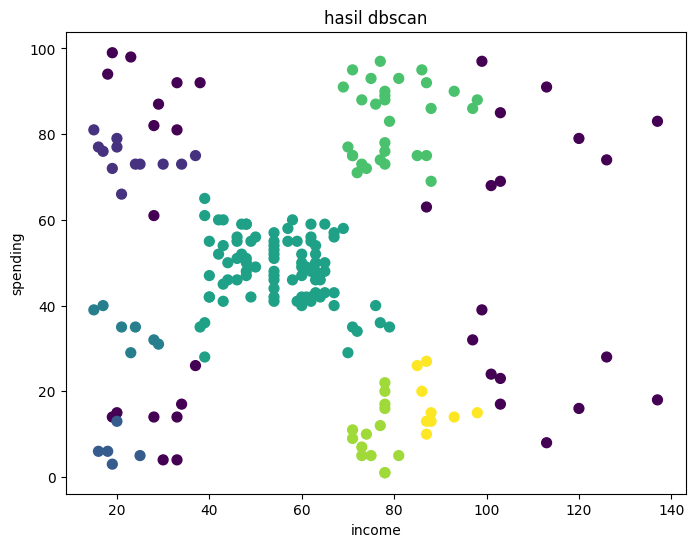

    eps  min_samples  clusters  noise  silhouette
0   0.2            3        13     44    0.469713
1   0.2            5         7     77    0.585613
2   0.2           10         1    129         NaN
3   0.3            3         9     14    0.472040
4   0.3            5         7     35    0.524328
5   0.3           10         4     88    0.607301
6   0.5            3         2      7    0.389247
7   0.5            5         2      8    0.387558
8   0.5           10         4     21    0.510668
9   0.8            3         1      0         NaN
10  0.8            5         1      0         NaN
11  0.8           10         1      4         NaN


In [8]:
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

print('jumlah anggota tiap label:', pd.Series(labels_dbscan).value_counts())
n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_dbscan = list(labels_dbscan).count(-1)
print(f'jumlah cluster: {n_clusters_dbscan}, jumlah noise: {n_noise_dbscan}')

plt.figure(figsize=(8, 6))
plt.scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'], c=labels_dbscan, cmap='viridis', s=50)
plt.title('hasil dbscan')
plt.xlabel('income')
plt.ylabel('spending')
plt.show()

# tabel coba-coba parameter
results = []
for eps in [0.2, 0.3, 0.5, 0.8]:
    for ms in [3, 5, 10]:
        db = DBSCAN(eps=eps, min_samples=ms)
        lbl = db.fit_predict(X_scaled)
        n_c = len(set(lbl)) - (1 if -1 in lbl else 0)
        n_ns = list(lbl).count(-1)
        score = silhouette_score(X_scaled[lbl != -1], lbl[lbl != -1]) if n_c > 1 and len(set(lbl[lbl != -1])) > 1 else np.nan
        results.append({'eps': eps, 'min_samples': ms, 'clusters': n_c, 'noise': n_ns, 'silhouette': score})
print(pd.DataFrame(results))

Analisis DBSCAN
kenaikan eps bikin cluster makin nyatu jd lebih sedikit tapi noise berkurang

min_samples yg lebih tinggi bikin titik yg agak longgar dianggap sbg noise

kalau eps terlalu kecil, kebanyakan titik dianggap noise, tapi kalau terlalu besar, semua jadi satu cluster besar

jumlah anggota cluster birch: 1    109
0     36
3     25
4     22
2      8
Name: count, dtype: int64
jumlah cluster: 5


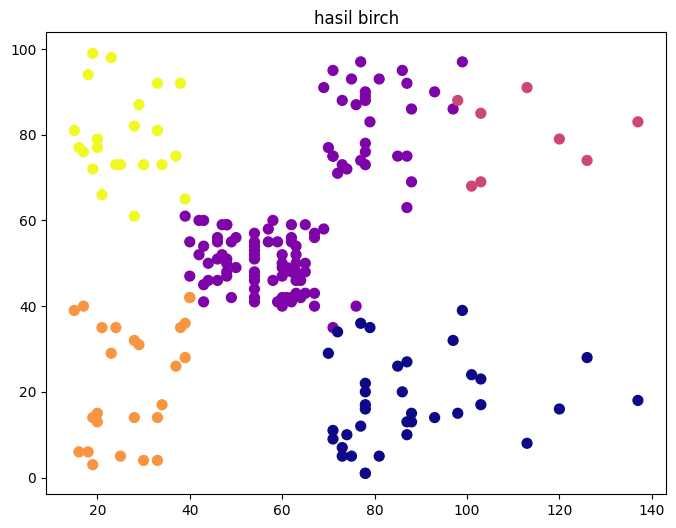

   threshold  clusters  silhouette
0        0.3         5    0.478062
1        0.5         5    0.414450
2        0.7         5    0.420676
3        1.0         4    0.388557


c:\Users\LEGION\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cluster\_birch.py:711: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


In [9]:
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)

print('jumlah anggota cluster birch:', pd.Series(labels_birch).value_counts())
print('jumlah cluster:', len(set(labels_birch)))

plt.figure(figsize=(8, 6))
plt.scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'], c=labels_birch, cmap='plasma', s=50)
plt.title('hasil birch')
plt.show()

birch_results = []
for th in [0.3, 0.5, 0.7, 1.0]:
    b = Birch(threshold=th, n_clusters=5)
    lbl = b.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, lbl)
    birch_results.append({'threshold': th, 'clusters': len(set(lbl)), 'silhouette': score})
print(pd.DataFrame(birch_results))

Analisis BIRCH
kalau threshold diperbesar, subcluster makin gampang digabung shg jumlah cluster akhir bisa mengecil

birch lgsg masukin semua titik ke cluster terdekat tanpa ada label noise -1 kaya dbscan

saat n_clusters ditentukan di awal, birch bakal maksa penggabungan subcluster sesuai jumlah itu

anggota cluster gmm: 0    84
1    39
3    33
4    23
2    21
Name: count, dtype: int64
contoh probabilitas keanggotaan:
 [[1.57689698e-05 1.88009163e-08 9.52031247e-04 5.20013085e-08
  9.99032129e-01]
 [1.62776204e-05 1.89596786e-04 9.99790184e-01 4.21013390e-23
  3.94154449e-06]
 [2.21339374e-19 9.52615737e-19 1.22549539e-12 1.86223280e-04
  9.99813777e-01]
 [1.05444778e-04 1.80087695e-04 9.99693745e-01 3.79390067e-21
  2.07229768e-05]
 [6.47301428e-05 3.84273231e-08 1.55669540e-03 4.75722704e-08
  9.98378488e-01]]


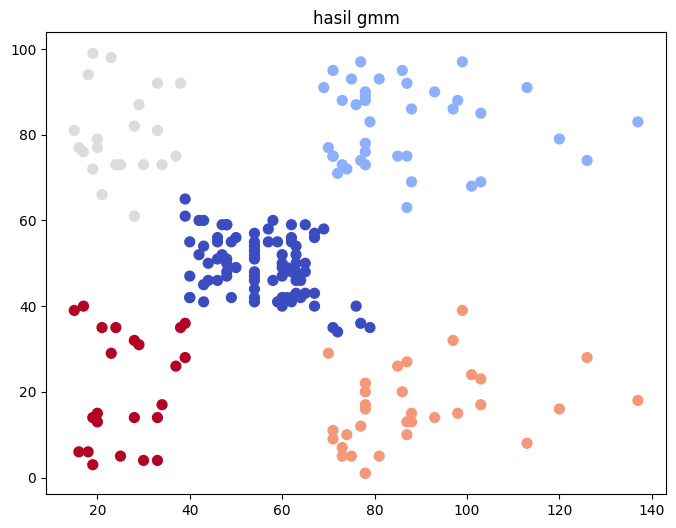

   n_components  silhouette          bic
0             2    0.379082  1153.904655
1             3    0.430190  1151.718274
2             4    0.413392  1103.790149
3             5    0.553689  1058.652252
4             6    0.516982  1074.682807
5             7    0.509057  1087.328517
6             8    0.430210  1102.370701


In [10]:
gmm = GaussianMixture(n_components=5, covariance_type='full', random_state=42)
labels_gmm = gmm.fit_predict(X_scaled)
probs = gmm.predict_proba(X_scaled)

print('anggota cluster gmm:', pd.Series(labels_gmm).value_counts())
print('contoh probabilitas keanggotaan:\n', probs[:5])

plt.figure(figsize=(8, 6))
plt.scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'], c=labels_gmm, cmap='coolwarm', s=50)
plt.title('hasil gmm')
plt.show()

gmm_eval = []
for k in range(2, 9):
    gm = GaussianMixture(n_components=k, random_state=42)
    lbl = gm.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, lbl)
    bic = gm.bic(X_scaled)
    gmm_eval.append({'n_components': k, 'silhouette': score, 'bic': bic})
print(pd.DataFrame(gmm_eval))

Analisis EM/GMM
probabilitas keanggotaan nunjukkin seberapa yakin model naruh suatu titik ke cluster tertentu (bisa soft clustering)

pas n_components diubah, bentuk sebaran cluster ngikutin jumlah gaussian yg diminta

bic yg lebih rendah nunjukkin model optimal tanpa overfitting, kadang ga selalu sejalan lurus sm silhouette score tertinggi

    model  clusters  noise  silhouette  davies_bouldin  calinski_harabasz
0  DBSCAN         7     35    0.524328        0.579955         185.575811
1   BIRCH         5      0    0.414450        0.697938         125.948605
2     GMM         5      0    0.553689        0.576010         244.940197


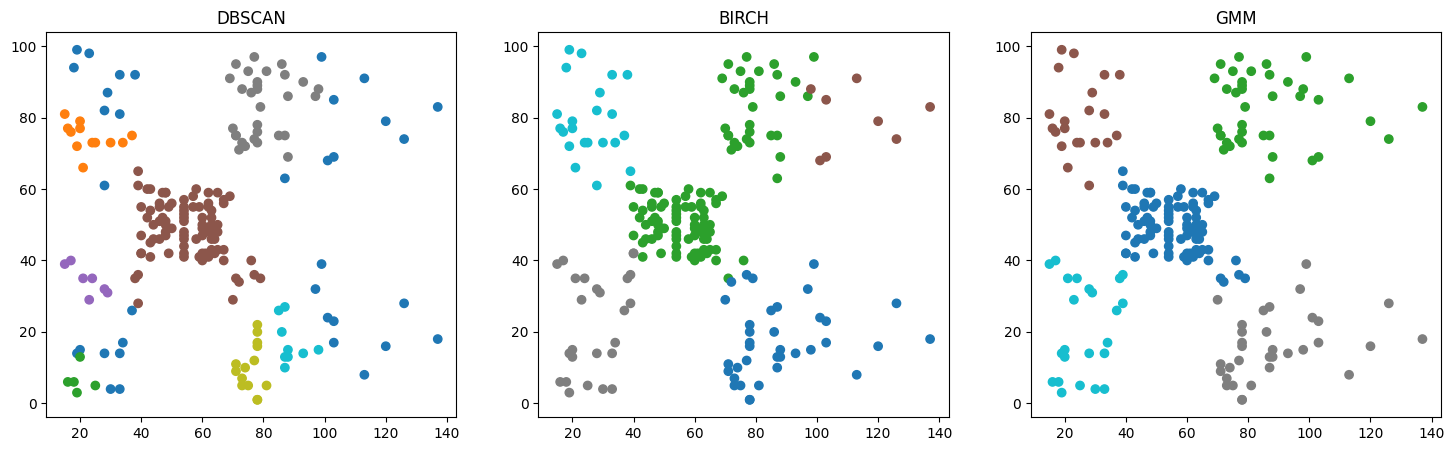

In [11]:
def eval_model(X_data, labels):
    valid_mask = labels != -1
    if len(set(labels[valid_mask])) <= 1:
        return np.nan, np.nan, np.nan
    X_v = X_data[valid_mask]
    l_v = labels[valid_mask]
    sil = silhouette_score(X_v, l_v)
    db = davies_bouldin_score(X_v, l_v)
    ch = calinski_harabasz_score(X_v, l_v)
    return sil, db, ch

metrics = []
for name, lbl in [('DBSCAN', labels_dbscan), ('BIRCH', labels_birch), ('GMM', labels_gmm)]:
    n_c = len(set(lbl)) - (1 if -1 in lbl else 0)
    n_ns = list(lbl).count(-1)
    sil, db, ch = eval_model(X_scaled, lbl)
    metrics.append({'model': name, 'clusters': n_c, 'noise': n_ns, 'silhouette': sil, 'davies_bouldin': db, 'calinski_harabasz': ch})

print(pd.DataFrame(metrics))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (name, lbl) in enumerate([('DBSCAN', labels_dbscan), ('BIRCH', labels_birch), ('GMM', labels_gmm)]):
    axes[i].scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'], c=lbl, cmap='tab10')
    axes[i].set_title(f'{name}')
plt.show()

| Aspek | DBSCAN | BIRCH | EM/GMM |
| --- | --- | --- | --- |
| Perlu menentukan jumlah cluster di awal? | tidak | ya | ya |
| Dapat memberi label noise secara eksplisit? | ya | tidak | tidak |
| Parameter yang paling memengaruhi hasil | eps, min_samples | threshold, n_clusters | n_components, covariance_type |
| Bentuk cluster yang dapat dimodelkan | arbitrary / sembarang | spherical / berbasis bola | elips / gaussian |
| Kelebihan | bisa deteksi noise dan bentuk bebas | cepat untuk data besar | fleksibel lewat probabilitas |
| Kekurangan | sensitif bgt sm parameter eps | kurang bagus buat data non-spherical | bisa lambat kalau komponen banyak |

7. analisis


1. mengapa fitur perlu di-scaling sebelum clustering?
karena rentang nilai annual income (15 sampe 137) jauh lebih besar daripada spending score (1 sampe 100). kalau ga di-scaling pake standardscaler, algoritma berbasis jarak kaya euclidean bakal bias ke annual income dan nganggep perubahannya jauh lebih penting drpd spending score, padahal kedua fitur ini punya bobot arti yg sama penting buat segmentasi customer

2. bagaimana perubahan parameter dbscan memengaruhi jumlah cluster dan noise?
kenaikan eps bikin radius tetangga makin luas sehingga titik-titik yg tadinya mencar bisa tergabung ke cluster terdekat, akibatnya jumlah cluster berkurang dan titik noise ikut turun drastis. sebaliknya kalau min_samples ditambah, syarat kepadatan makin ketat jadi banyak titik yg terpaksa di-label sebagai noise (-1) dan cluster bisa pecah atau malah hilang

3. bagaimana parameter threshold dan n_clusters memengaruhi birch?
parameter threshold nentuin radius maksimum subcluster di dalam pohon, jadi kalau threshold dibikin makin besar, subcluster gampang digabung sehingga jumlah cluster akhir makin sedikit. sementara n_clusters di akhir bertindak sebagai batas target berapa banyak cluster yg mau dibentuk setelah proses perangkuman pohon selesai

4. apa makna probabilitas keanggotaan gmm dan bagaimana em menggunakannya?
probabilitas keanggotaan nunjukkin tingkat keyakinan atau seberapa besar peluang suatu titik data masuk ke masing-masing komponen gaussian. algoritma em make nilai ini secara iteratif di mana langkah e-step ngitung probabilitas keanggotaan berdasarkan parameter saat ini, terus m-step update parameter distribusi (mean & kovarians) buat maksimalkan kemungkinan data tersebut

5. model mana yang paling mudah diinterpretasikan pada dataset ini? jelaskan alasannya.
gmm atau birch jauh lebih gampang diinterpretasikan dibanding dbscan. alasannya karena gmm dan birch konsisten ngehasilin pembagian cluster yg rapi sesuai sebaran visual tanpa ninggalin banyak titik noise (-1) yg bikin bingung pas bikin profil segmentasi customer

6. apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? jika berbeda, apa kemungkinan penyebabnya?
belum tentu sama persis karena setiap metrik nilaiin aspek yg beda, misal silhouette nilaiin jarak pemisahan antar cluster, sedangkan davies-bouldin nilaiin rasio kesamaan antar cluster terdekat. perbedaan hasil ini biasa terjadi karena bentuk cluster mall customer gak semua bener-bener bujur sangkar atau terpisah linear sempurna

7. jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. berikan nama deskriptif pada cluster jika memungkinkan.
berdasarkan hasil cluster (dibagi 5 kelompok utama):
* cluster pendapatan rendah, spending rendah -> disebut kategori hemat
* cluster pendapatan rendah, spending tinggi -> disebut kategori boros impulsif
* cluster pendapatan sedang, spending sedang -> disebut kategori moderat atau standar
* cluster pendapatan tinggi, spending rendah -> disebut kategori cermat atau selektif
* cluster pendapatan tinggi, spending tinggi -> disebut kategori prioritas atau vip

8. apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?
penggunaan 2 fitur (income & spending) cuma nampilin satu sudut pandang perilaku belanja aja tanpa tahu umur, gender, atau riwayat transaksi lain yg bisa bikin segmentasi lebih akurat. selain itu, ukuran dataset yg kecil bikin model gampang overfitting dan kurang kuat kalau dipake buat generalisasi data customer dalam skala beneran yg masif

8. kesimpulan dan saran


1. algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
berdasarkan eksperimen, gmm (gaussian mixture model) dan birch ngasih hasil yg paling berguna dan rapi bgt buat segmentasi mall customer. mereka bsa ngebentuk cluster yg jelas sesuai sebaran visual tanpa ninggalin titik noise (-1) yg bikin bingung pas ditarik profilnya, beda sama dbscan yg agak sensitif bgt sm parameter eps dan gampang bgt nge-drop data jd noise

2. parameter apa yang dipilih dan mengapa?
buat dbscan dipilih eps=0.3 dan min_samples=5 sbg titik awal yg masuk akal buat nyari kepadatan data. buat birch dipilih threshold=0.5 dan n_clusters=5 biar jumlah cluster akhir pas dan gampang di-mapping. sedangkan buat gmm dipake n_components=5, covariance_type='full', dan random_state=42 supaya dapet 5 kelompok segmen customer yg stabil dan konsisten stiap kali di-run

3. apa perbedaan utama dbscan, birch, dan em/gmm yang kalian pelajari?
dbscan fokus ke kepadatan lokal dan bisa deteksi noise tnpa nentuin jumlah cluster di awal tapi susah diatur eps-nya. birch pake struktur pohon buat ngerangkum data jd subcluster secara cepet tnpa deteksi noise. sementara em/gmm pake model probabilistik (distribusi gaussian) yg ngasih probabilitas keanggotaan soft clustering ke stiap titik data

4. eksperimen lanjutan apa yang dapat dilakukan?
eksperimen selanjutnya bisa nambahin fitur lain kaya umur (age) atau jenis kelamin (gender stlh di-encoding), nyoba scaling model pake minmaxscaler, atau nerapin teknik PCA dlu sblm clustering biar tau performa model pas dimensi data ditambah